---
course_code: 02BMSBI24365
course_title: AI and ML in Bioinformatics
unit: Unit 3 — Deep Learning for Biological Data
submodule: 3.1 Artificial Neural Networks (ANNs)
scheduled_sessions: Sessions 13 & 14 (Days 13 & 14)
document_type: Practical Laboratory Notebook
ai_tier: Full AI (Learning Aid)
---

# 🧬 Hands-On: Building an Artificial Neural Network in Keras

In our theory primers ([3.1 Basics of ANNs](3.1_neural_networks_primer.md) and [3.1 How Neural Networks Learn](3.1_how_neural_networks_learn.md)), we worked through the mathematical mechanisms of deep learning:
* How neurons compute weighted sums ($z = \mathbf{w}^T\mathbf{x} + b$) and pass them through activation functions (ReLU, Sigmoid).
* How loss functions measure the clinical cost of misdiagnoses.
* How backpropagation uses the chain rule to assign credit and guide gradient descent.

When studying theory, it can feel like a heavy mountain of calculus and linear algebra. 

**Here is the great revelation of applied deep learning:** In Python, modern frameworks like **Keras and TensorFlow** handle all of the calculus, vectorization, and gradient calculations automatically under the hood! 

Building, training, and evaluating a neural network takes **less than 15 lines of code**.

```text
               THE 4-STEP APPLIED KERAS WORKFLOW
        ┌──────────────────────────────────────────────┐
        │ 1. DEFINE ARCHITECTURE                       │
        │    model = models.Sequential([layers...])    │
        ├──────────────────────────────────────────────┤
        │ 2. COMPILE (Loss & Optimizer)                │
        │    model.compile(optimizer='adam', loss=...) │
        ├──────────────────────────────────────────────┤
        │ 3. TRAIN (The Iterative Calibration Loop)    │
        │    history = model.fit(X_train, y_train...)  │
        ├──────────────────────────────────────────────┤
        │ 4. PREDICT & EVALUATE                        │
        │    probabilities = model.predict(X_test)     │
        └──────────────────────────────────────────────┘
```

In this notebook, we bring our exact **two-biomarker breast cancer cohort (*HER2/ERBB2* and *ESR1*)** and our **2-hidden-neuron architecture** from the theory primer into working code, step-by-step.


---

## Step 0: Environment Setup & Reproducible Imports

We import NumPy, Matplotlib, Scikit-learn's `train_test_split`, and TensorFlow's `keras` API:
* `train_test_split`: Standard partitioning into training (80%) and held-out validation/test (20%) cohorts.
* `layers.Dense`: Standard fully-connected neural network layer ($z = \mathbf{w}^T\mathbf{x} + b$).
* `models.Sequential`: Linear stack of layers passing data forward.
* `layers.Dropout`: Regularization layer to prevent overfitting on biological data.


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# If tensorflow is not yet installed in your conda environment, uncomment and run:
# !pip install tensorflow

import tensorflow as tf
from tensorflow.keras import layers, models

# Set fixed random seeds for exact reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Set clean visualization styling
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

print(f"TensorFlow Version: {tf.__version__}")
print("Environment initialized successfully. Ready to build our neural network!")


TensorFlow Version: 2.21.0
Environment initialized successfully. Ready to build our neural network!


---

## Step 1: The Biological Toy Dataset & Train/Test Split

In clinical oncology, breast cancer biopsies are routinely characterized by cell-surface and nuclear receptor expression:
1. **Biomarker 1 ($x_1$): *HER2* (*ERBB2*) Expression** — Receptor tyrosine kinase oncogene. Overexpression indicates high-grade, proliferative malignancy.
2. **Biomarker 2 ($x_2$): *ESR1* (Estrogen Receptor 1) Expression** — Hormone receptor driving luminal tumor proliferation.

We create a synthetic cohort of **100 patient biopsies** ($50$ Benign, $50$ Malignant) standardized to healthy baseline ($z$-scores):
* **Benign / Low-Risk ($y = 0$):** Centered at lower expression ($x_1 \approx -0.8, x_2 \approx -0.6$).
* **Malignant / High-Risk ($y = 1$):** Centered at elevated oncogenic expression ($x_1 \approx +0.9, x_2 \approx +0.7$).

### Leak-Free Validation Strategy: `train_test_split`
To adhere to clinical ML validation hygiene, we split our 100-patient cohort into:
* **Training Cohort (80 patients):** Used by the network to learn weights via backpropagation.
* **Testing Cohort (20 patients):** Held-out unseen biopsies used exclusively to evaluate diagnostic generalization.

We also define our exact **walkthrough patient** from the theory primer:
$$\text{Patient X: } x_1 (\text{HER2}) = 1.5, \quad x_2 (\text{ESR1}) = 0.8 \quad (\text{True Diagnosis: Malignant}, y = 1)$$


In [18]:
# 1. Generate 50 Benign Biopsies (Class 0)
n_samples_per_class = 50
X_benign = np.random.randn(n_samples_per_class, 2) * 0.6 + np.array([-0.8, -0.6])
y_benign = np.zeros(n_samples_per_class)

# 2. Generate 50 Malignant Biopsies (Class 1)
X_malignant = np.random.randn(n_samples_per_class, 2) * 0.6 + np.array([0.9, 0.7])
y_malignant = np.ones(n_samples_per_class)

# Combine into full patient cohort (100 samples)
X = np.vstack([X_benign, X_malignant])
y = np.concatenate([y_benign, y_malignant])

# 3. Standard Train/Test Split (80% Train, 20% Held-out Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y  # Preserves 50/50 Benign/Malignant ratio in both splits
)

# Our specific test patient from the theory primer
patient_walkthrough = np.array([[1.5, 0.8]])

print(f"Total Cohort:    {len(y)} patient biopsies")
print(f"Training Split:  {X_train.shape[0]} patients ({int(np.sum(y_train))} Malignant / {int(len(y_train) - np.sum(y_train))} Benign)")
print(f"Testing Split:   {X_test.shape[0]} patients ({int(np.sum(y_test))} Malignant / {int(len(y_test) - np.sum(y_test))} Benign)")
print(f"Walkthrough Pt:  HER2 = {patient_walkthrough[0, 0]}, ESR1 = {patient_walkthrough[0, 1]} (Ground Truth: Malignant, y = 1)")


Total Cohort:    100 patient biopsies
Training Split:  80 patients (40 Malignant / 40 Benign)
Testing Split:   20 patients (10 Malignant / 10 Benign)
Walkthrough Pt:  HER2 = 1.5, ESR1 = 0.8 (Ground Truth: Malignant, y = 1)


### Visualizing the Patient Biomarker Space

Let us plot our training and testing cohorts in 2D biomarker space. Notice the biological cluster separation, along with the location of our walkthrough patient:


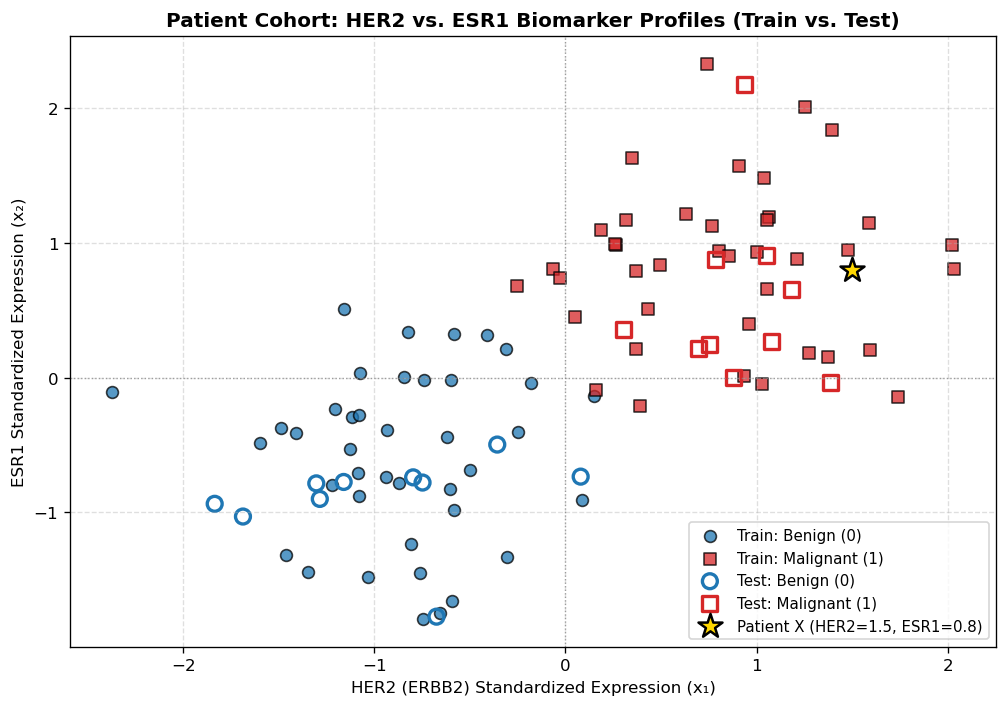

In [19]:
plt.figure(figsize=(8.5, 6))

# Plot Training Biopsies
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='#1f77b4', s=50, edgecolors='k', alpha=0.75, label='Train: Benign (0)')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='#d62728', s=50, marker='s', edgecolors='k', alpha=0.75, label='Train: Malignant (1)')

# Plot Held-out Test Biopsies (unfilled markers)
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1],
            color='none', edgecolors='#1f77b4', s=80, lw=2.0, label='Test: Benign (0)')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
            color='none', edgecolors='#d62728', s=80, marker='s', lw=2.0, label='Test: Malignant (1)')

# Highlight our theory walkthrough patient (golden star)
plt.scatter(patient_walkthrough[0, 0], patient_walkthrough[0, 1],
            color='gold', s=230, marker='*', edgecolors='black', lw=1.5,
            label='Patient X (HER2=1.5, ESR1=0.8)', zorder=5)

plt.axhline(0, color='gray', linestyle=':', lw=0.8, alpha=0.7)
plt.axvline(0, color='gray', linestyle=':', lw=0.8, alpha=0.7)
plt.title("Patient Cohort: HER2 vs. ESR1 Biomarker Profiles (Train vs. Test)", fontsize=12, fontweight='bold')
plt.xlabel("HER2 (ERBB2) Standardized Expression (x₁)", fontsize=10)
plt.ylabel("ESR1 Standardized Expression (x₂)", fontsize=10)
plt.legend(loc='lower right', frameon=True, fontsize=9)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


---

## Step 2: Defining the Architecture (Matching Theory Exactly)

In [3.1 Basics of ANNs](3.1_neural_networks_primer.md) and [3.1 How Neural Networks Learn](3.1_how_neural_networks_learn.md), our exact walkthrough architecture had:
* **Input Layer:** 2 nodes ($x_1 = \text{HER2}, x_2 = \text{ESR1}$).
* **Hidden Layer:** **2 neurons ($h_1, h_2$)** using **ReLU** activation ($\text{ReLU}(z) = \max(0, z)$).
* **Output Layer:** **1 diagnostic neuron** using **Sigmoid** activation ($\sigma(z) \in [0.0, 1.0]$).

In Keras, we define this exact architecture using `models.Sequential()`:


In [20]:
# Define the neural network architecture (2 inputs -> 2 hidden neurons -> 1 output)
model = models.Sequential([
    # Hidden Layer: 2 neurons, ReLU activation, 2 inputs (HER2, ESR1)
    layers.Dense(units=2, activation='relu', input_shape=(2,), name="hidden_layer"),
    
    # Output Layer: 1 neuron, Sigmoid activation for malignancy probability
    layers.Dense(units=1, activation='sigmoid', name="output_neuron")
])

# Print structural summary
model.summary()


/Users/boss/Conda/miniconda3/envs/gcu-aiml-bioinfo/lib/python3.10/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer (Dense)            │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_neuron (Dense)           │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

### Dissecting the Parameter Count (Connecting to Theory)

Look at `Total params: 9` in the summary table above:
1. **Hidden Layer (`hidden_layer`):**
   * Weights: $2 \text{ inputs} \times 2 \text{ neurons} = 4$ weights ($w_{1,1}, w_{1,2}, w_{2,1}, w_{2,2}$).
   * Biases: $1 \text{ bias per neuron} = 2$ biases ($b_1, b_2$).
   * Total: $4 + 2 = \mathbf{6 \text{ parameters}}$.
2. **Output Layer (`output_neuron`):**
   * Weights: $2 \text{ hidden inputs} \times 1 \text{ neuron} = 2$ weights ($w_1^{[2]}, w_2^{[2]}$).
   * Bias: $1 \text{ bias} = 1$ bias ($b^{[2]}$).
   * Total: $2 + 1 = \mathbf{3 \text{ parameters}}$.

**Total across the entire network: $6 + 3 = \mathbf{9 \text{ trainable parameters}}$!**

Notice how this matches our theory primer identically: these 9 parameters correspond exactly to the 4 hidden weights, 2 hidden biases, 2 output weights, and 1 output bias we calculated by hand!


---

## Step 3: What Does an Untrained Model Do? (Random Guesses)

Right now, the 9 parameters inside `model` are initialized with **random numbers**. 

Let us feed Patient X ($x = [1.5, 0.8]$) into our untrained model to observe what happens:


In [21]:
# Predict on Patient X BEFORE training
prob_before = model.predict(patient_walkthrough, verbose=0)[0, 0]

print("=== Prediction BEFORE Training ===")
print(f"Patient X Biomarkers: HER2 = 1.5, ESR1 = 0.8 (True Reality: Malignant, y = 1.0)")
print(f"Untrained Prediction: P(Malignant) = {prob_before:.4f} ({prob_before*100:.1f}%)")
print("Diagnosis Verdict:    ", "Malignant" if prob_before >= 0.5 else "Benign")
print("\nTakeaway: The model has not learned yet! Its prediction is purely a random initialization artifact.")


=== Prediction BEFORE Training ===
Patient X Biomarkers: HER2 = 1.5, ESR1 = 0.8 (True Reality: Malignant, y = 1.0)
Untrained Prediction: P(Malignant) = 0.7963 (79.6%)
Diagnosis Verdict:     Malignant

Takeaway: The model has not learned yet! Its prediction is purely a random initialization artifact.


---

## Step 4: Compiling the Model (Referee & Learning Strategy)

To turn random guessing into clinical intelligence, we configure two essential components using `model.compile()`:

1. **Loss Function (`loss='binary_crossentropy'`):**
   * The objective referee that compares the predicted probability ($\hat{y}$) to true pathology ($y$).
   * Binary Cross-Entropy severely penalizes confident wrong diagnoses ($-\ln(\hat{y})$).
2. **Optimizer (`optimizer='adam'`):**
   * The optimization engine that implements gradient descent ($w_{\text{new}} = w_{\text{old}} - \alpha \nabla \mathcal{L}$).
   * Adam adapts the step size for each parameter automatically and uses momentum to glide through flat error regions.
3. **Evaluation Metrics (`metrics=['accuracy']`):**
   * Tracks percentage of correct diagnoses for human monitoring.


In [22]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully! The loss referee and Adam optimizer are ready.")


Model compiled successfully! The loss referee and Adam optimizer are ready.


---

## Step 5: Training the Model (`model.fit`) — The Calibration Loop

Now we trigger the training feedback loop using `model.fit()`:
* **`epochs=50`:** The network will review the 80 training patients 50 times.
* **`batch_size=16`:** The network reviews 16 patient biopsies in morning rounds, computes the loss, runs backpropagation via the chain rule, and updates all 9 weights simultaneously.
* **`validation_data=(X_test, y_test)`:** After each epoch, Keras evaluates the model on the held-out test cohort to monitor generalization without allowing test data to leak into weight updates.

Watch how **training loss drops** while **validation accuracy rises**!


In [23]:
# Train the model with validation monitoring
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

print("\nTraining completed! All 9 parameters have been calibrated.")


Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9750 - loss: 0.5281 - val_accuracy: 1.0000 - val_loss: 0.5315
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9750 - loss: 0.5249 - val_accuracy: 1.0000 - val_loss: 0.5285
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9750 - loss: 0.5216 - val_accuracy: 1.0000 - val_loss: 0.5255
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9750 - loss: 0.5184 - val_accuracy: 1.0000 - val_loss: 0.5226
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9875 - loss: 0.5153 - val_accuracy: 1.0000 - val_loss: 0.5196
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9875 - loss: 0.5122 - val_accuracy: 1.0000 - val_loss: 0.5167
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9875 - loss: 0.5091 - val_accuracy: 1.0000 - val_loss: 0.5138
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9875 - loss: 0.5060 - val_accuracy: 1.0000 - val_loss: 0.5109
Epoch 9

---

## Step 6: Visualizing the Training Progress (Walking Down the Mountain)

In theory, we described gradient descent as **walking down a foggy mountain toward the lowest loss valley**. 

Let us plot the actual training and validation histories recorded by Keras:


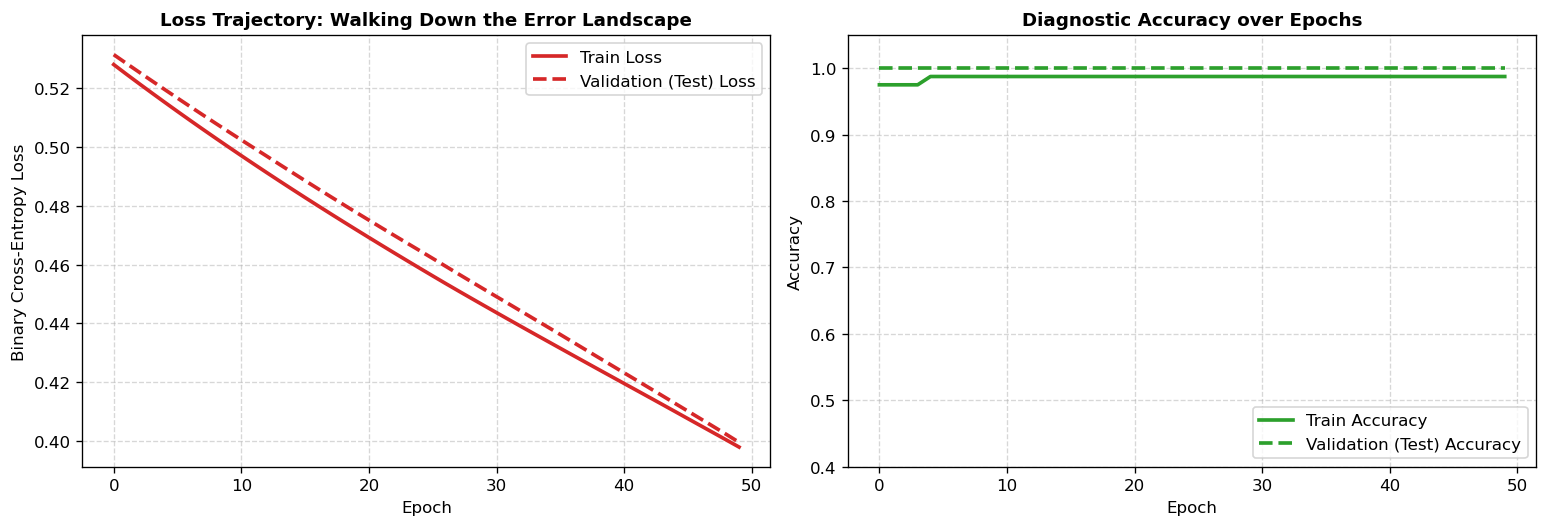

Final Training Loss:      0.3978
Final Validation Loss:    0.3995
Final Validation Accuracy: 100.0%


In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Binary Cross-Entropy Loss over Epochs
ax1.plot(history.history['loss'], color='#d62728', lw=2.2, label='Train Loss')
ax1.plot(history.history['val_loss'], color='#d62728', lw=2.2, linestyle='--', label='Validation (Test) Loss')
ax1.set_title("Loss Trajectory: Walking Down the Error Landscape", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("Binary Cross-Entropy Loss", fontsize=10)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Diagnostic Accuracy over Epochs
ax2.plot(history.history['accuracy'], color='#2ca02c', lw=2.2, label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], color='#2ca02c', lw=2.2, linestyle='--', label='Validation (Test) Accuracy')
ax2.set_title("Diagnostic Accuracy over Epochs", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("Accuracy", fontsize=10)
ax2.set_ylim(0.4, 1.05)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Final Training Loss:      {history.history['loss'][-1]:.4f}")
print(f"Final Validation Loss:    {history.history['val_loss'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]*100:.1f}%")


---

## Step 7: Visualizing the Learned Biological Decision Boundary

How does the trained neural network separate malignant from benign patients in biomarker space?

We generate a fine 2D grid over the *HER2* and *ESR1* axes and compute the model's predicted probability for every point. The contour line at $P = 0.50$ represents the network's **decision boundary**:


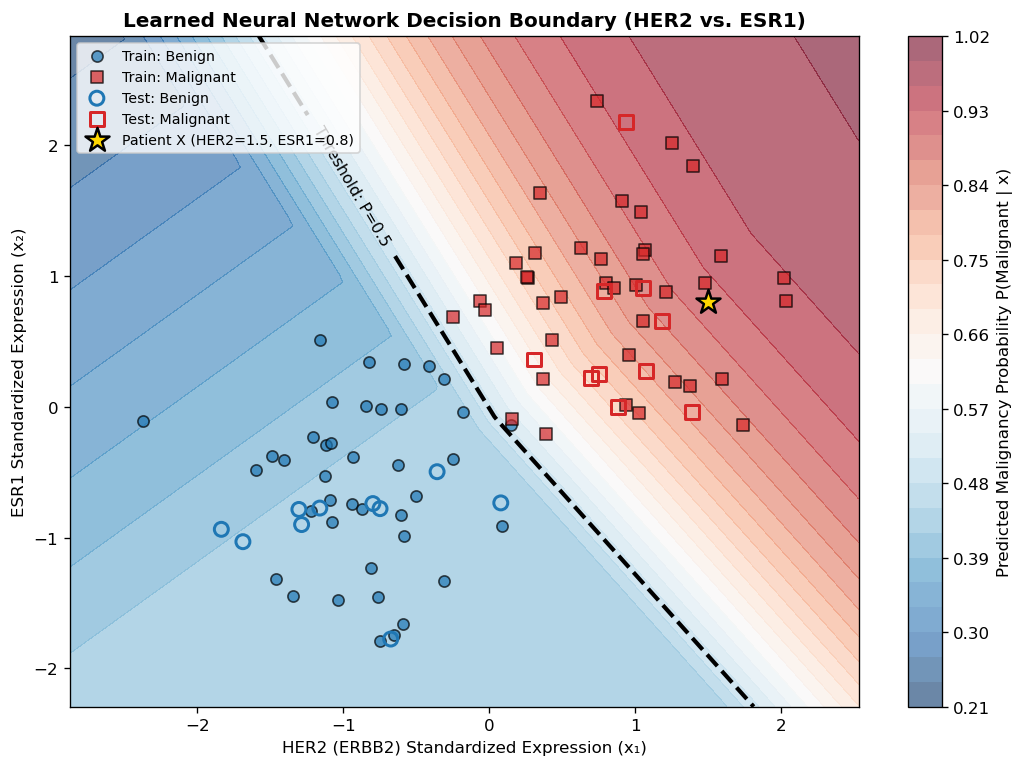

Takeaway:
  • The blue region represents confident Benign predictions (P < 0.5).
  • The red region represents confident Malignant predictions (P > 0.5).
  • Both training and unseen test samples are accurately partitioned!
  • Patient X sits firmly in the confident malignant territory.


In [25]:
# Create dense 2D grid across biomarker space
x1_grid = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200)
x2_grid = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200)
XX1, XX2 = np.meshgrid(x1_grid, x2_grid)
grid_points = np.c_[XX1.ravel(), XX2.ravel()]

# Predict malignancy probabilities across the entire grid
Z_probs = model.predict(grid_points, verbose=0).reshape(XX1.shape)

# Plot decision boundary and confidence landscape
plt.figure(figsize=(9, 6.5))

# Plot probability contours
contour = plt.contourf(XX1, XX2, Z_probs, levels=25, cmap='RdBu_r', alpha=0.6)
cbar = plt.colorbar(contour)
cbar.set_label("Predicted Malignancy Probability P(Malignant | x)", fontsize=10)

# Draw clinical decision threshold (P = 0.50)
boundary = plt.contour(XX1, XX2, Z_probs, levels=[0.5], colors='black', linewidths=2.5, linestyles='--')
plt.clabel(boundary, inline=True, fmt='Threshold: P=0.5', fontsize=9.5)

# Overlay Training Biopsies
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
            color='#1f77b4', s=45, edgecolors='k', alpha=0.7, label='Train: Benign')
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
            color='#d62728', s=45, marker='s', edgecolors='k', alpha=0.7, label='Train: Malignant')

# Overlay Test Biopsies
plt.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1],
            color='none', edgecolors='#1f77b4', s=70, lw=1.8, label='Test: Benign')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
            color='none', edgecolors='#d62728', s=70, marker='s', lw=1.8, label='Test: Malignant')

# Overlay our walkthrough patient
plt.scatter(patient_walkthrough[0, 0], patient_walkthrough[0, 1],
            color='gold', s=230, marker='*', edgecolors='black', lw=1.5,
            label='Patient X (HER2=1.5, ESR1=0.8)', zorder=5)

plt.title("Learned Neural Network Decision Boundary (HER2 vs. ESR1)", fontsize=12, fontweight='bold')
plt.xlabel("HER2 (ERBB2) Standardized Expression (x₁)", fontsize=10)
plt.ylabel("ESR1 Standardized Expression (x₂)", fontsize=10)
plt.legend(loc='upper left', frameon=True, fontsize=8.5)
plt.tight_layout()
plt.show()

print("Takeaway:")
print("  • The blue region represents confident Benign predictions (P < 0.5).")
print("  • The red region represents confident Malignant predictions (P > 0.5).")
print("  • Both training and unseen test samples are accurately partitioned!")
print("  • Patient X sits firmly in the confident malignant territory.")


---

## Step 8: Formal Evaluation & Re-testing Patient X

### 8.1 Evaluating the Held-Out Test Cohort
We run `model.evaluate()` on our 20 held-out test patients to verify clinical performance:


In [26]:
# Formal evaluation on held-out test cohort
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"=== Held-Out Test Cohort Performance (n = {len(y_test)}) ===")
print(f"  • Test Loss:     {test_loss:.4f}")
print(f"  • Test Accuracy: {test_accuracy * 100:.1f}%\n")

# Predict on Patient X AFTER training
prob_after = model.predict(patient_walkthrough, verbose=0)[0, 0]

print("=== Diagnostic Comparison for Patient X ===")
print(f"Biomarker Profile: HER2 = {patient_walkthrough[0,0]}, ESR1 = {patient_walkthrough[0,1]} (True Diagnosis: Malignant, y = 1.0)")
print("-" * 60)
print(f"  • BEFORE Training: P(Malignant) = {prob_before:.4f} ({prob_before*100:.1f}%)  [Random Guess]")
print(f"  • AFTER Training:  P(Malignant) = {prob_after:.4f} ({prob_after*100:.1f}%)  [Trained Intelligence]")
print("-" * 60)
if prob_after >= 0.5:
    print(f"Final Clinical Verdict: POSITIVE FOR MALIGNANCY (Confidence: {prob_after*100:.1f}%)")
else:
    print(f"Final Clinical Verdict: NEGATIVE FOR MALIGNANCY (Confidence: {(1-prob_after)*100:.1f}%)")


=== Held-Out Test Cohort Performance (n = 20) ===
  • Test Loss:     0.3995
  • Test Accuracy: 100.0%

=== Diagnostic Comparison for Patient X ===
Biomarker Profile: HER2 = 1.5, ESR1 = 0.8 (True Diagnosis: Malignant, y = 1.0)
------------------------------------------------------------
  • BEFORE Training: P(Malignant) = 0.7963 (79.6%)  [Random Guess]
  • AFTER Training:  P(Malignant) = 0.9162 (91.6%)  [Trained Intelligence]
------------------------------------------------------------
Final Clinical Verdict: POSITIVE FOR MALIGNANCY (Confidence: 91.6%)


---

## Step 9: Adding Regularization (Dropout) in 1 Line of Code

In [3.1 How Neural Networks Learn](3.1_how_neural_networks_learn.md), we introduced **Dropout**—the biological analogy of genetic pathway redundancy that prevents the network from memorizing small clinical cohorts.

In Keras, adding Dropout is as simple as inserting `layers.Dropout(rate)` between layers:


In [27]:
# Build a regularized architecture with Dropout
regularized_model = models.Sequential([
    # Hidden Layer 1: 4 neurons with ReLU
    layers.Dense(units=4, activation='relu', input_shape=(2,), name="dense_1"),
    
    # Regularization: Randomly silence 25% of neurons during each training pass
    layers.Dropout(rate=0.25, name="dropout_1"),
    
    # Hidden Layer 2: 2 neurons with ReLU
    layers.Dense(units=2, activation='relu', name="dense_2"),
    
    # Output Layer: 1 neuron with Sigmoid
    layers.Dense(units=1, activation='sigmoid', name="output_neuron")
])

regularized_model.summary()

print("\nNotice how easy Keras makes it to incorporate advanced regularization!")


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_neuron (Dense)           │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)


Notice how easy Keras makes it to incorporate advanced regularization!


---

## 📌 Student Challenge & Interactive Sandbox

### Challenge Task

